# Vanishing Gradients: Depth vs. Gradient Magnitude

**AIGC 5500 — Week 2, Part 1 — "In the live session" demo**

Trains the same small sigmoid network at three depths (2, 8, and 20 hidden
layers) and reads the per-layer gradient after a single backward pass, so
the collapse toward zero with depth is visible directly rather than
asserted.

This is the instructor-facing version of the Part 1 "Try it" exercise —
same idea, run at three depths side by side instead of one.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

_ = torch.manual_seed(0)

## The network

A feedforward network of a given depth, every hidden layer followed by a
sigmoid activation. Width is fixed at 32 so depth is the only thing that
changes between runs.

In [2]:
class DeepSigmoidNet(nn.Module):
    """A feedforward network of a given depth, every hidden layer
    followed by a sigmoid activation. Width is fixed at 32 so depth is
    the only thing that changes between runs.
    """

    def __init__(self, depth, width=32, in_features=32):
        super().__init__()
        layers = []
        n_in = in_features
        for _ in range(depth):
            layers.append(nn.Linear(n_in, width))
            n_in = width
        self.hidden = nn.ModuleList(layers)
        self.out = nn.Linear(width, 1)

    def forward(self, x):
        for layer in self.hidden:
            x = torch.sigmoid(layer(x))
        return self.out(x)

## Running one depth

Build the network, initialize every layer the same fixed way (deliberately
**not** He/Xavier — Part 2 is where that fix arrives), run one forward and
backward pass on random data, and read off the mean absolute gradient of
each hidden layer's weights.

In [3]:
def per_layer_grad_norms(model):
    """Mean absolute gradient of each hidden layer's weight matrix,
    in forward order (layer 0 is closest to the input).
    """
    return [layer.weight.grad.abs().mean().item() for layer in model.hidden]


def run_depth(depth, seed=0, width=32, in_features=32, n_samples=64):
    torch.manual_seed(seed)
    model = DeepSigmoidNet(depth=depth, width=width, in_features=in_features)

    # Same fixed initialization scheme at every depth, so depth is the
    # only variable — a small fixed std, deliberately not He/Xavier,
    # since the point of this demo is to see the problem before Part 2
    # fixes it.
    for layer in model.hidden:
        nn.init.normal_(layer.weight, mean=0.0, std=0.5)
        nn.init.zeros_(layer.bias)

    x = torch.randn(n_samples, in_features)
    y = torch.randn(n_samples, 1)

    preds = model(x)
    loss = nn.functional.mse_loss(preds, y)
    loss.backward()

    return per_layer_grad_norms(model)

## Run it at three depths

2, 8, and 20 hidden layers, everything else held fixed.

In [4]:
depths = [2, 8, 20]
results = {}

for depth in depths:
    results[depth] = run_depth(depth, seed=0)
    first, last = results[depth][0], results[depth][-1]
    ratio = last / first if first > 0 else float("inf")
    print(f"depth {depth:>3}:  layer-0 grad = {first:.2e}   "
          f"last-layer grad = {last:.2e}   last is {ratio:,.0f}x larger")

depth   2:  layer-0 grad = 1.71e-03   last-layer grad = 2.94e-03   last is 2x larger
depth   8:  layer-0 grad = 2.20e-05   last-layer grad = 1.24e-03   last is 56x larger
depth  20:  layer-0 grad = 3.55e-09   last-layer grad = 3.87e-03   last is 1,089,995x larger


Read layer 0 (closest to the input, furthest from the loss) against the
last layer (closest to the loss) within each run: at depth 2 they are
within the same order of magnitude; at depth 20 the input-side layer's
gradient is orders of magnitude smaller — it has almost stopped learning
before training even begins.

## Every layer, at every depth

In [5]:
def print_table(results):
    depths = list(results.keys())
    max_layers = max(len(v) for v in results.values())

    header = f"{'Layer':>7} | " + " | ".join(f"depth={d:>3}" for d in depths)
    print(header)
    print("-" * len(header))
    for i in range(max_layers):
        row = [f"{i:>7} |"]
        for d in depths:
            norms = results[d]
            if i < len(norms):
                row.append(f" {norms[i]:.2e}   ")
            else:
                row.append(f" {'—':>9} ")
        print(" ".join(row))

print_table(results)

  Layer | depth=  2 | depth=  8 | depth= 20
-------------------------------------------
      0 |  1.71e-03     2.20e-05     3.55e-09   
      1 |  2.94e-03     2.41e-05     1.08e-08   
      2 |          —   4.06e-05     2.04e-08   
      3 |          —   5.99e-05     7.84e-08   
      4 |          —   1.85e-04     1.14e-07   
      5 |          —   3.05e-04     2.11e-07   
      6 |          —   6.28e-04     4.35e-07   
      7 |          —   1.24e-03     1.02e-06   
      8 |          —           —   2.26e-06   
      9 |          —           —   3.74e-06   
     10 |          —           —   7.99e-06   
     11 |          —           —   1.68e-05   
     12 |          —           —   2.62e-05   
     13 |          —           —   5.76e-05   
     14 |          —           —   1.38e-04   
     15 |          —           —   2.86e-04   
     16 |          —           —   4.10e-04   
     17 |          —           —   1.05e-03   
     18 |          —           —   1.65e-03   
     19 |

## Plot it

Log scale on the y-axis — on a linear scale the depth-2 and depth-8 curves
would be indistinguishable from zero next to depth-20's range.

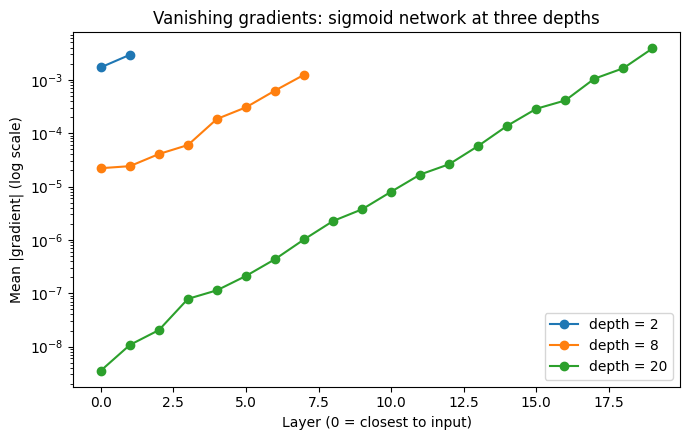

In [6]:
plt.figure(figsize=(7, 4.5))
for depth, norms in results.items():
    # x-axis: layer index from input to output, so all three curves
    # start at the same point (closest to the input) and the vanishing
    # effect lines up visually.
    x = list(range(len(norms)))
    plt.plot(x, norms, marker="o", label=f"depth = {depth}")
plt.yscale("log")
plt.xlabel("Layer (0 = closest to input)")
plt.ylabel("Mean |gradient| (log scale)")
plt.title("Vanishing gradients: sigmoid network at three depths")
plt.legend()
plt.tight_layout()
plt.savefig("vanishing_gradients.png", dpi=150)
plt.show()

## Takeaway

The gradient a parameter receives is a product of local derivatives, one
per layer between that parameter and the loss (Week 1, Part 2). A sigmoid's
local derivative is at most 0.25, so every extra layer multiplies the
gradient by something meaningfully less than 1. At depth 20 that product
has compounded enough to make the input-side layers effectively untrainable
— which is exactly the problem Part 2's initialization and normalization
fixes address.